# Part 1: Know the workload

Back-of-the-envelope estimates for one GPU on `traces/azure_conversation.csv` (Llama-3-8B, one A100-80GB). Fill the four TODOs in `analysis/workload.py` first (`pytest tests/test_workload.py`); this notebook only calls them.

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
if not (ROOT / "traces").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from analysis import workload as wl
from analysis.workload import arrival_rates, kv_bytes_per_token, kv_in_use, load_trace, predict_queue_wait

df = load_trace(ROOT / "traces" / "azure_conversation.csv")
span = df.arrived_at.max() - df.arrived_at.min()
print(f"n={len(df)}  span={span:.0f}s  native QPS={(len(df) - 1) / span:.2f}")

n=19366  span=3502s  native QPS=5.53


## Arrivals over time

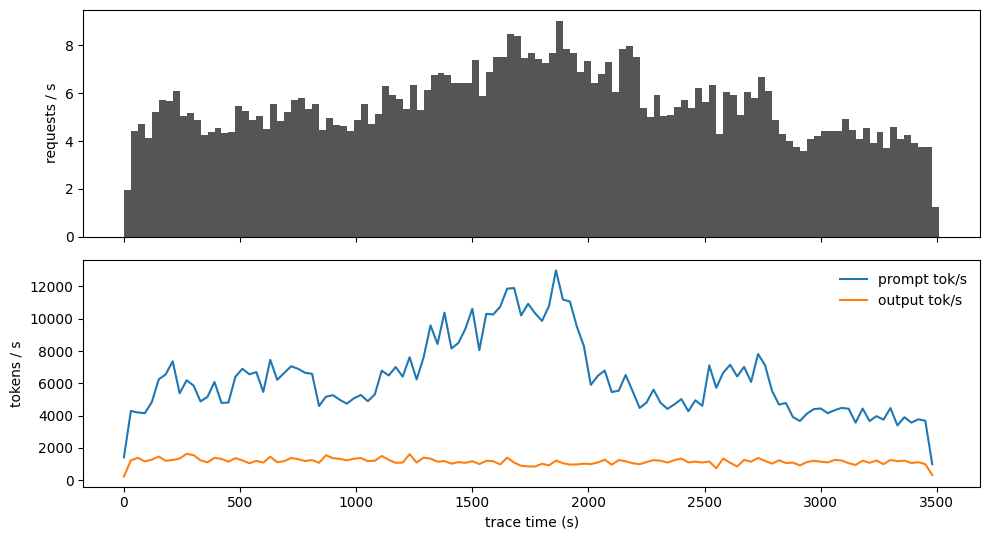

In [3]:
BIN_S = 30.0
rates = arrival_rates(df, BIN_S)

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
ax0.bar(rates.bin_start, rates.req_per_s, width=BIN_S, align="edge", color="#555555")
ax0.set_ylabel("requests / s")
ax1.plot(rates.bin_start, rates.prompt_tok_per_s, label="prompt tok/s")
ax1.plot(rates.bin_start, rates.output_tok_per_s, label="output tok/s")
ax1.set_ylabel("tokens / s")
ax1.set_xlabel("trace time (s)")
ax1.legend(frameon=False)
fig.tight_layout()
plt.show()

## Predicted queue wait (one GPU)

predicted wait P50 0.59s  P99 72.13s  max 73.5s
longest stretch above the 2 s target: 1192-2272 s


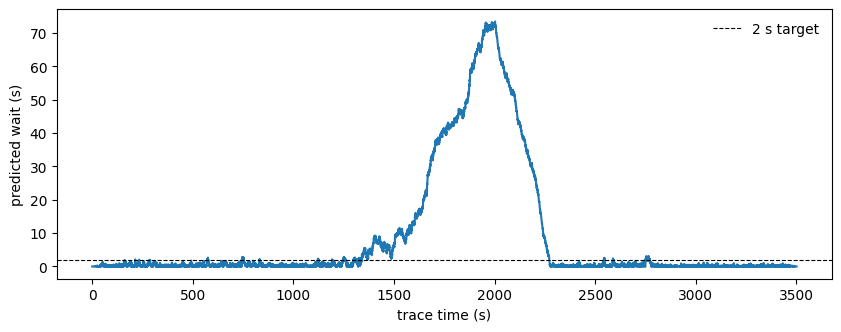

In [4]:
WAIT_TARGET_S = 2.0   # P99 wait target used for the rest of the assignment

w = predict_queue_wait(df)
print(f"predicted wait P50 {np.median(w):.2f}s  P99 {np.quantile(w, 0.99):.2f}s  max {w.max():.1f}s")

def longest_late_stretch(t, wait, merge_gap_s=60.0):
    """Longest time range where requests wait over the target (gaps under a minute merged).
    Part 2's notebook uses the same rule."""
    late = t[wait > WAIT_TARGET_S]
    if len(late) == 0:
        return "never"
    breaks = np.flatnonzero(np.diff(late) > merge_gap_s)
    starts, ends = np.r_[late[0], late[breaks + 1]], np.r_[late[breaks], late[-1]]
    i = np.argmax(ends - starts)
    return f"{starts[i]:.0f}-{ends[i]:.0f} s"

print(f"longest stretch above the 2 s target: {longest_late_stretch(df.arrived_at.to_numpy(), w)}")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(df.arrived_at, w)
ax.axhline(WAIT_TARGET_S, color="k", linestyle="--", linewidth=0.8, label="2 s target")
ax.set_xlabel("trace time (s)")
ax.set_ylabel("predicted wait (s)")
ax.legend(frameon=False)
plt.show()

## KV-cache memory in use (one GPU)

KV per token: 128 KiB   model weights: 13.0 GiB (transformer layers only)
KV in use (estimate): mean 10.0 GiB   peak 26.7 GiB at t=2010s


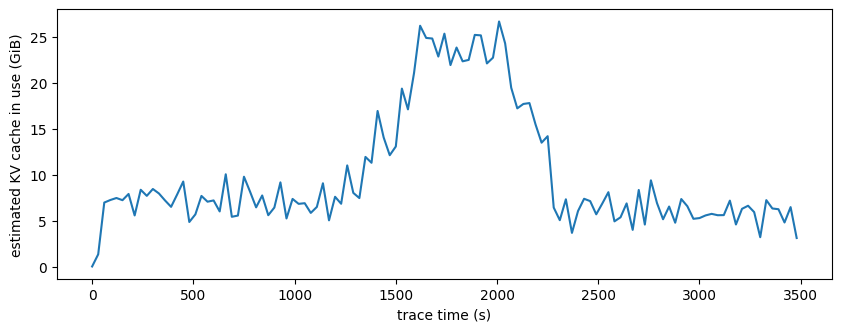

In [5]:
print(f"KV per token: {kv_bytes_per_token() / 1024:.0f} KiB   model weights: {wl.MODEL_WEIGHTS_GIB} GiB (transformer layers only)")

kv = kv_in_use(df, w, BIN_S)
print(f"KV in use (estimate): mean {kv.kv_gib.mean():.1f} GiB   peak {kv.kv_gib.max():.1f} GiB "
      f"at t={kv.bin_start[kv.kv_gib.idxmax()]:.0f}s")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(kv.bin_start, kv.kv_gib)
ax.set_xlabel("trace time (s)")
ax.set_ylabel("estimated KV cache in use (GiB)")
plt.show()

## Questions

The wait target is **P99 under 2 s**: 99% of requests should wait less than 2 s.

**Q1.** Does your model predict that one GPU meets the 2 s target? If not, when does it miss, and is that stretch driven by more requests, longer prompts, or both? Cite the arrival plot.

**Your answer:**
No, this target is not met. The stretch that fails to meet the target is from 1192 to 2272 seconds in the trace. This stretch is driven by more requests, as the graph showing requests/s and tokens/s is highest during that middle stretch. Longer prompts also may be contributing as the tokens/s plot shows a sharper peak during this stretch than the requests/s plot, so these requests are also likely a bit longer as well.

**Q2.** What are the average and the peak KV-cache memory in use, and when is the peak? Which of these GPUs has enough memory for this trace: 24 GiB (L4), 40 GiB (A100), 48 GiB (L40S), 80 GiB (A100 / H100)? Count the model weights and keep 10% of memory free. Which would you pick if you sized by the average instead? Then rerun `kv_in_use` with `max_batch_size` set very large: what peak do you get? Which of the two peaks better estimates what the GPU actually holds, and why?

**Your answer:**
Average KV cache in use is 10GB. The peak is 26.7GB, which occurs at t=2010. 

Model weights are 13GB, therefore you need at least 13GB + 26.7GB = 39.7GB. 
In order to keep 10% of memory free (~4GB), only the 48GB L40S and the 80GB A100/H100 would have enough memory. 

If picking by average KV cache used (10GB), then you would need at least 10GB + 13GB = 23GB. With 10% of memory free, this would require 23 + 2.3 = 25.3 GB, so only the 24GB L4 wouldn't work, but all the other GPUs would be sufficient.

With a batch size of 512 instead of 128, the peak KV cache use becomes 94.4 GB, but the previously caluclated peak would be a better estimate as this batch size would not be feasible to use.

KV in use (estimate): mean 17.1 GiB   peak 94.4 GiB at t=1950s


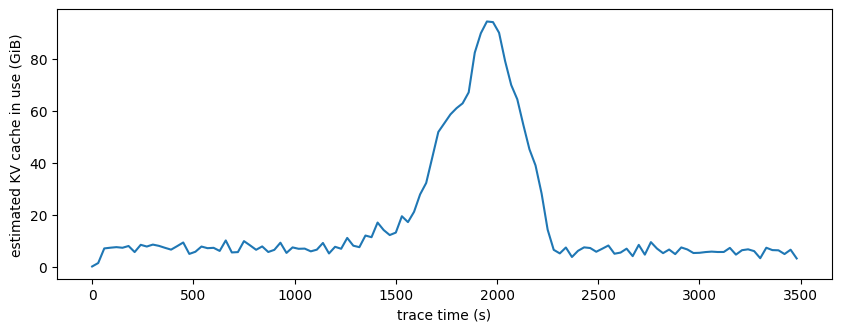

In [8]:
# Q2 scratch
kv = kv_in_use(df, w, BIN_S, max_batch_size=512)
print(f"KV in use (estimate): mean {kv.kv_gib.mean():.1f} GiB   peak {kv.kv_gib.max():.1f} GiB "
      f"at t={kv.bin_start[kv.kv_gib.idxmax()]:.0f}s")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(kv.bin_start, kv.kv_gib)
ax.set_xlabel("trace time (s)")
ax.set_ylabel("estimated KV cache in use (GiB)")
plt.show()

**Q3.** At 128 tokens per 30 ms step, one GPU decodes at most 4,267 tokens/s. What is that throughput if a step takes 20 ms or 50 ms, or if the batch holds only 64? Rerun `predict_queue_wait` with each. How much does the P99 wait move compared with the change in throughput, and why? Then set `decode_tok_per_s=float("inf")`: in this model, can faster decode alone meet the 2 s target? If not, what is the bottleneck?

**Your answer:**

20ms/step: throughput = 6400 tok/s

50ms/step: throughput = 2560 tok/s

batch_size=64: throughput = 2133 tok/s

The P99 wait increases as throughput decreases in a seemingly linear fashion. This is because if throughput decreases, each request will take longer, therefore increasing waiting times of later requests.
With infinite decode throughput, the P99 target is still not met, so the bottleneck is likely in prefill not decode.

In [12]:
# Q3 scratch: predict_queue_wait(df, decode_tok_per_s=batch / step_s)
# infinitely fast decode: predict_queue_wait(df, decode_tok_per_s=float("inf"))
batch = 128
w = predict_queue_wait(df, decode_tok_per_s=batch / 20)
print(f"predicted wait P50 {np.median(w):.2f}s  P99 {np.quantile(w, 0.99):.2f}s  max {w.max():.1f}s")

w = predict_queue_wait(df, decode_tok_per_s=batch / 50)
print(f"predicted wait P50 {np.median(w):.2f}s  P99 {np.quantile(w, 0.99):.2f}s  max {w.max():.1f}s")

w = predict_queue_wait(df, decode_tok_per_s=64 / 30)
print(f"predicted wait P50 {np.median(w):.2f}s  P99 {np.quantile(w, 0.99):.2f}s  max {w.max():.1f}s")

w = predict_queue_wait(df, decode_tok_per_s=float("inf"))
print(f"predicted wait P50 {np.median(w):.2f}s  P99 {np.quantile(w, 0.99):.2f}s  max {w.max():.1f}s")


predicted wait P50 334977.76s  P99 628858.19s  max 637163.8s
predicted wait P50 838576.15s  P99 1574565.86s  max 1595401.8s
predicted wait P50 1006442.29s  P99 1889801.75s  max 1914814.5s
predicted wait P50 0.03s  P99 3.38s  max 4.9s


**Q4.** Record your predictions for Part 2: the P99 wait, the longest stretch above the 2 s target (printed above), and the peak KV-cache memory (GiB).

| Prediction | Value |
|---|---|
| P99 wait | 72.13 |
| Longest stretch above the 2 s target | 1192-2272 s |
| Peak KV-cache memory (GiB) | 26.7 GB |